In [ ]:
!git clone https://github.com/khoagrai/BTL_ML.git
%cd BTL_ML

from preprocess import load_and_preprocess_data

X_train, X_test, y_train, y_test = load_and_preprocess_data(
    "WA_Fn-UseC_-Telco-Customer-Churn.csv"
)

print("Kích thước tập Train:", X_train.shape)
print("Kích thước tập Test :", X_test.shape)

Kích thước tập Train: (5625, 30)
Kích thước tập Test : (1407, 30)


In [ ]:
from sklearn.ensemble import RandomForestClassifier

rf_base = RandomForestClassifier(random_state=42)
rf_base.fit(X_train, y_train)

print("Đã huấn luyện xong mô hình Random Forest mặc định!")

Đã huấn luyện xong mô hình Random Forest mặc định!


In [ ]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    'n_estimators': [100, 150],
    'max_depth': [8, 10],
    'class_weight': [None, 'balanced'],
}

grid_rf = GridSearchCV(
    estimator=RandomForestClassifier(random_state=42),
    param_grid=param_grid,
    cv=3,
    scoring='f1',
    n_jobs=-1,
)
grid_rf.fit(X_train, y_train)

best_rf = grid_rf.best_estimator_
print('Bộ tham số tốt nhất tìm được:', grid_rf.best_params_)

Bộ tham số tốt nhất tìm được: {'class_weight': 'balanced', 'max_depth': 8, 'n_estimators': 150}


In [ ]:
import pandas as pd

importances = pd.Series(
    best_rf.feature_importances_, index=X_train.columns
).sort_values(ascending=False)
top10_cols = importances.head(10).index.tolist()

print("10 đặc trưng quan trọng nhất:", top10_cols)

rf_top10 = RandomForestClassifier(**grid_rf.best_params_, random_state=42)
rf_top10.fit(X_train[top10_cols], y_train)

10 đặc trưng quan trọng nhất: ['tenure', 'TotalCharges', 'Contract_Two year', 'MonthlyCharges', 'InternetService_Fiber optic', 'PaymentMethod_Electronic check', 'Contract_One year', 'OnlineSecurity_Yes', 'TechSupport_Yes', 'StreamingMovies_No internet service']


RandomForestClassifier(class_weight='balanced', max_depth=8, n_estimators=150,
                       random_state=42)

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)


def evaluate(model, X_data, y_data, name):
  y_pred = model.predict(X_data)
  y_prob = model.predict_proba(X_data)[:, 1]
  return {
      'Phiên bản mô hình': name,
      'Accuracy': round(accuracy_score(y_data, y_pred), 4),
      'Precision': round(precision_score(y_data, y_pred), 4),
      'Recall': round(recall_score(y_data, y_pred), 4),
      'F1-Score': round(f1_score(y_data, y_pred), 4),
      'ROC-AUC': round(roc_auc_score(y_data, y_prob), 4),
  }


df_results = pd.DataFrame([
    evaluate(rf_base, X_test, y_test, '1. RF Mặc định (30 đặc trưng)'),
    evaluate(best_rf, X_test, y_test, '2. RF Đã tinh chỉnh (30 đặc trưng)'),
    evaluate(
        rf_top10,
        X_test[top10_cols],
        y_test,
        '3. RF Đã tinh chỉnh (Top 10 đặc trưng)',
    ),
])

display(df_results)

,Phiên bản mô hình,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,1. RF Mặc định (30 đặc trưng),0.7882,0.6234,0.5134,0.5630,0.8156
1,2. RF Đã tinh chỉnh (30 đặc trưng),0.7377,0.5042,0.8021,0.6192,0.8379
2,3. RF Đã tinh chỉnh (Top 10 đặc trưng),0.7491,0.5184,0.7914,0.6265,0.8334


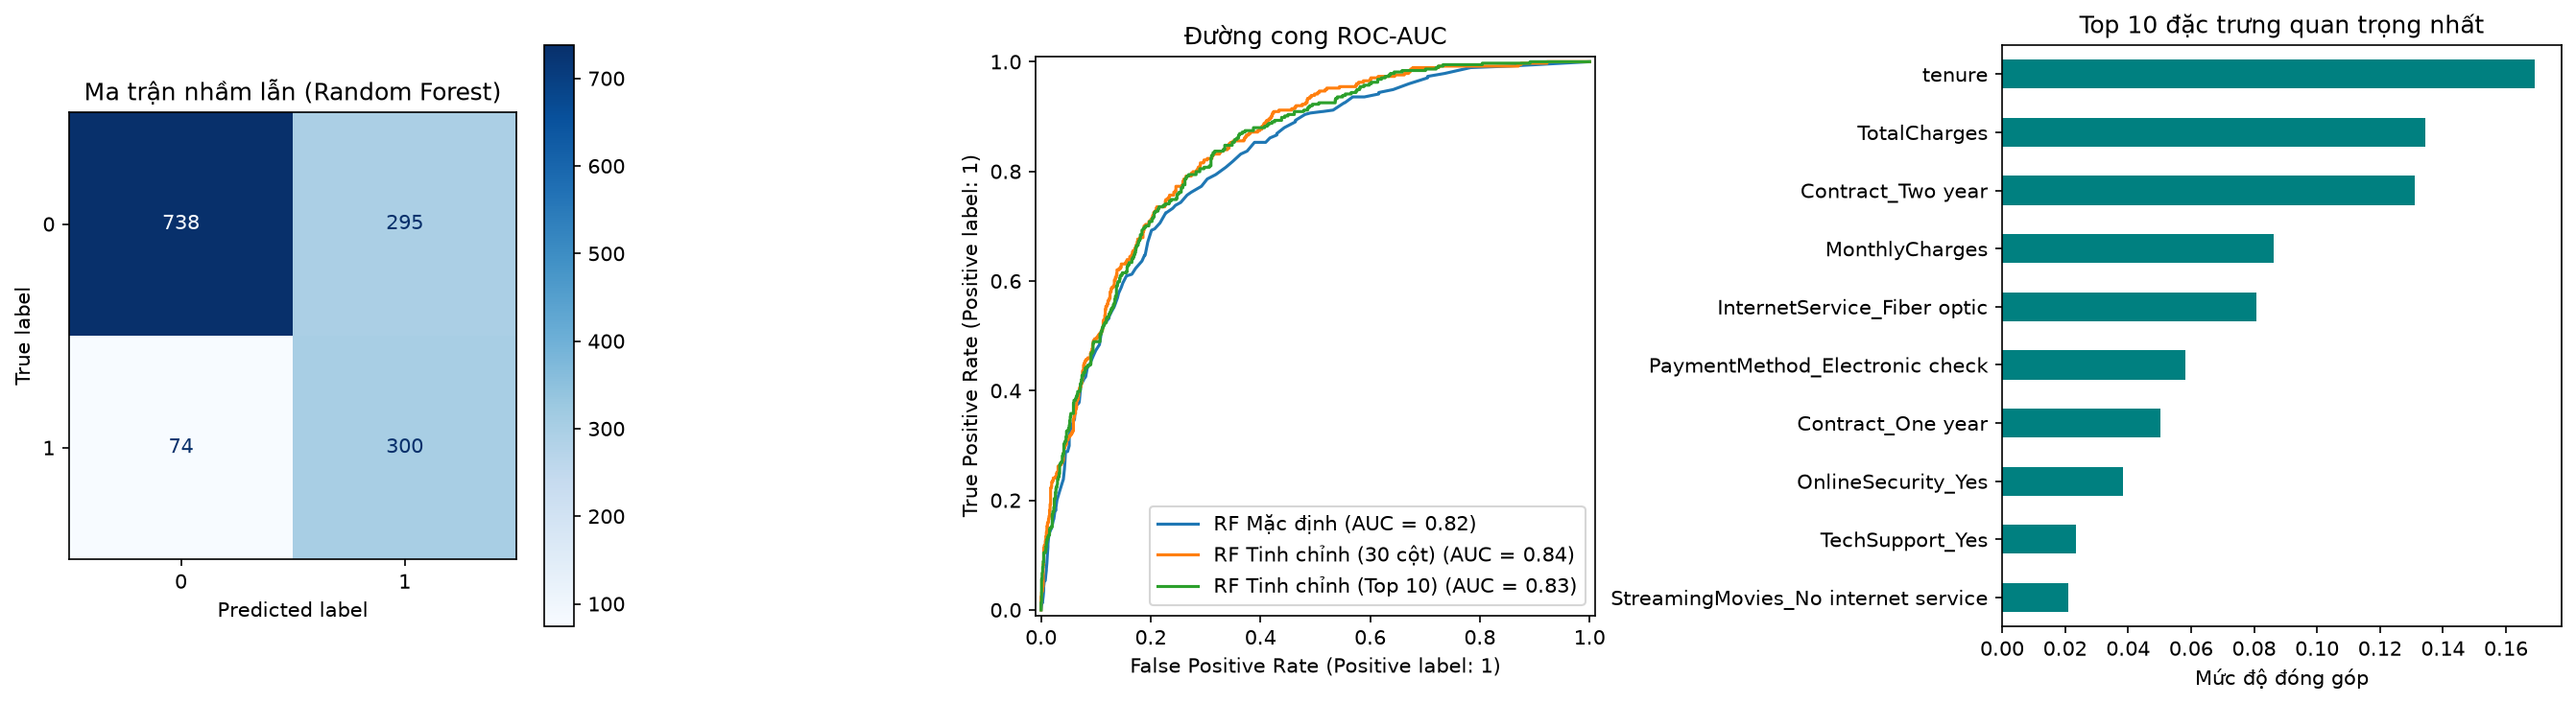

Đã lưu file mô hình: random_forest_model.pkl


In [ ]:
import joblib
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

ConfusionMatrixDisplay.from_estimator(
    best_rf, X_test, y_test, ax=axes[0], cmap='Blues'
)
axes[0].set_title('Ma trận nhầm lẫn (Random Forest)')

RocCurveDisplay.from_estimator(
    rf_base, X_test, y_test, ax=axes[1], name='RF Mặc định'
)
RocCurveDisplay.from_estimator(
    best_rf, X_test, y_test, ax=axes[1], name='RF Tinh chỉnh (30 cột)'
)
RocCurveDisplay.from_estimator(
    rf_top10,
    X_test[top10_cols],
    y_test,
    ax=axes[1],
    name='RF Tinh chỉnh (Top 10)',
)
axes[1].set_title('Đường cong ROC-AUC')

importances.head(10).sort_values().plot(
    kind='barh', ax=axes[2], color='teal'
)
axes[2].set_title('Top 10 đặc trưng quan trọng nhất')
axes[2].set_xlabel('Mức độ đóng góp')

plt.tight_layout()
plt.show()

joblib.dump(best_rf, 'random_forest_model.pkl')
print('Đã lưu file mô hình: random_forest_model.pkl')